> **Prerequisite:** run `01_data_pipeline_and_baselines.ipynb` first in the same kernel. This notebook uses `X_cell_tensor`, `X_drug_tensor`, `y_tensor`, the validation tensors, and `DrugResponseDataset` defined there.

In [ ]:
# VAE Pretraining for Gene Expression Compression

#Goal: Train a Variational Autoencoder to compress 17,737-dimensional gene expression vectors into a lower-dimensional latent representation. 
 #   This latent vector will later be used with drug fingerprints to predict drug response.

In [49]:
#import
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

In [50]:
class CellExpressionDataset(Dataset):
    def __init__(self, X_cell):
        self.X_cell = X_cell
    def __len__(self):
        return len(self.X_cell)
    def __getitem__(self, idx):
        return self.X_cell[idx]

In [51]:
cell_train_dataset = CellExpressionDataset(X_cell_tensor)
cell_train_loader = DataLoader(
    cell_train_dataset,
    batch_size = 64,
    shuffle = True
)

In [52]:
cell_batch = next(iter(cell_train_loader))
print(cell_batch.shape)

torch.Size([64, 17737])


In [55]:
#Build VAE skeleton
class GeneExpressionVAE(nn.Module):
    def __init__(self, input_dim=17737, latent_dim=128):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 1024),
            nn.ReLU(),
            nn.Linear(1024,256),
            nn.ReLU()
        )

        self.mu_layer = nn.Linear(256, latent_dim)
        self.logvar_layer = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256,1024),
            nn.ReLU(),
            nn.Linear(1024, input_dim)
        )

    def encode(self,x):
        h = self.encoder(x)
        mu = self.mu_layer(h)
        logvar = self.logvar_layer(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        z =  mu + std * eps
        return z

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstruction = self.decode(z)
        return reconstruction, mu, logvar
            

In [56]:
#test forward pass
vae = GeneExpressionVAE(input_dim=17737, latent_dim=128)
reconstruction, mu, logvar = vae(cell_batch)

print("Input:", cell_batch.shape)
print("Reconstruction:", reconstruction.shape)
print("Mu:", mu.shape)
print("Logvar:", logvar.shape)

Input: torch.Size([64, 17737])
Reconstruction: torch.Size([64, 17737])
Mu: torch.Size([64, 128])
Logvar: torch.Size([64, 128])


In [58]:
def vae_loss(reconstruction, x, mu, logvar, beta=1e-4):
    recon_loss = nn.functional.mse_loss(reconstruction, x)

    kl_loss = -0.5 * torch.mean(
    1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss

In [59]:
#test loss
loss, recon_loss, kl_loss = vae_loss(
    reconstruction, 
    cell_batch,
    mu,
    logvar
)
print("Total loss:", loss.item())
print("Reconstruction loss:", recon_loss.item())
print("KL loss:", kl_loss.item())

Total loss: 27.826467514038086
Reconstruction loss: 27.826444625854492
KL loss: 0.22217190265655518


In [65]:
#train vae
vae = GeneExpressionVAE(input_dim=17737, latent_dim=128)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-4)

num_epochs = 10
beta = 1e-4

vae_train_losses = []

for epoch in range(num_epochs):
    vae.train()
    total_loss = 0
    for cell_batch in cell_train_loader:
        reconstruction, mu, logvar = vae(cell_batch)
        loss, recon_loss, kl_loss = vae_loss(
        reconstruction,
        cell_batch,
        mu,
        logvar,
        beta=beta
        )
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(cell_train_loader)
    vae_train_losses.append(avg_loss)

    print(f"Epoch {epoch+1}: VAE Loss={avg_loss:.4f}")

Epoch 1: VAE Loss=1.2517
Epoch 2: VAE Loss=0.6527
Epoch 3: VAE Loss=0.5490
Epoch 4: VAE Loss=0.4968
Epoch 5: VAE Loss=0.4707
Epoch 6: VAE Loss=0.4439
Epoch 7: VAE Loss=0.4122
Epoch 8: VAE Loss=0.3846
Epoch 9: VAE Loss=0.3615
Epoch 10: VAE Loss=0.3403


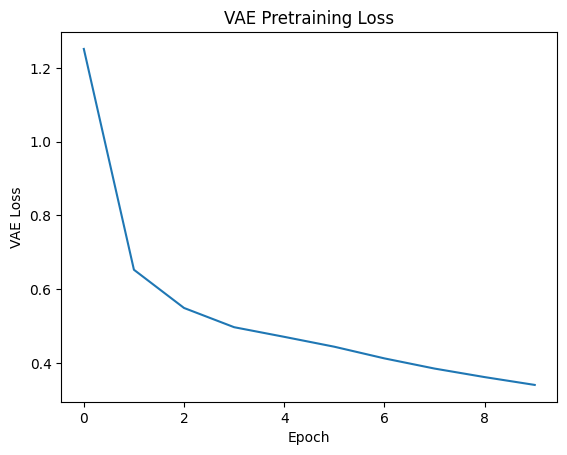

In [66]:
plt.plot(vae_train_losses)
plt.xlabel("Epoch")
plt.ylabel("VAE Loss")
plt.title("VAE Pretraining Loss")
plt.show()

In [67]:
vae.eval()
with torch.no_grad():
    mu, logvar = vae.encode(X_cell_tensor)
    X_cell_latent= mu
print(X_cell_latent.shape)

torch.Size([64892, 128])


In [68]:
latent_dataset = DrugResponseDataset(
    X_drug_tensor,
    X_cell_latent,
    y_tensor
)
latent_loader = DataLoader(
    latent_dataset,
    batch_size=64,
    shuffle=True
)

In [78]:
class VAEDrugResponseRegressor(nn.Module):
    def __init__(self):
        super().__init__()

        self.drug_encoder = nn.Sequential(
        nn.Linear(2048,256),
        nn.ReLU(),
        nn.Dropout(0.2)
        )

        self.cell_encoder = nn.Sequential(
        nn.Linear(128,128),
        nn.ReLU(),
        nn.Dropout(0.2)
        )

        self.regression_head = nn.Sequential(
        nn.Linear(384, 128),
        nn.ReLU(),
        nn.Linear(128,1)
        )

    def forward(self, drug, cell_latent):
        drug_emb = self.drug_encoder(drug)
        cell_emb = self.cell_encoder(cell_latent)

        combined = torch.cat((drug_emb, cell_emb), dim=1)
        
        output = self.regression_head(combined)

        return output.squeeze()

In [79]:
drug_batch, latent_batch, label_batch = next(iter(latent_loader))

vae_regressor = VAEDrugResponseRegressor()
preds = vae_regressor(drug_batch, latent_batch)
print(preds.shape)

torch.Size([64])


In [80]:
vae_regressor = VAEDrugResponseRegressor()
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(vae_regressor.parameters(), lr=1e-4)
num_epochs=10
vae_reg_train_losses=[]
for epoch in range(num_epochs):
    vae_regressor.train()
    total_loss = 0
    for drug_batch, latent_batch, label_batch in latent_loader:
        preds = vae_regressor(drug_batch, latent_batch)
        loss = loss_fn(preds, label_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(latent_loader)
    vae_reg_train_losses.append(avg_loss)
    print(f"Epoch {epoch+1}: VAE-Regression Train Loss={avg_loss:4f}")
    

Epoch 1: VAE-Regression Train Loss=2.827869
Epoch 2: VAE-Regression Train Loss=1.909115
Epoch 3: VAE-Regression Train Loss=1.835542
Epoch 4: VAE-Regression Train Loss=1.788596
Epoch 5: VAE-Regression Train Loss=1.766128
Epoch 6: VAE-Regression Train Loss=1.751514
Epoch 7: VAE-Regression Train Loss=1.728297
Epoch 8: VAE-Regression Train Loss=1.711367
Epoch 9: VAE-Regression Train Loss=1.694745
Epoch 10: VAE-Regression Train Loss=1.684040


In [84]:
vae.eval()
with torch.no_grad():
    mu_valid, logvar_valid = vae.encode(X_valid_cell_tensor)
    X_valid_cell_latent = mu_valid

In [85]:
valid_latent_dataset = DrugResponseDataset(
    X_valid_drug_tensor,
    X_valid_cell_latent,
    y_valid_tensor
)
valid_latent_loader = DataLoader(
    valid_latent_dataset,
    batch_size=64,
    shuffle=False
)


In [86]:
vae_regressor.eval()
all_preds = []
all_labels = []
with torch.no_grad():
    for drug_batch, latent_batch, label_batch in valid_latent_loader:
        preds = vae_regressor(drug_batch, latent_batch)
        all_preds.extend(preds.numpy())
        all_labels.extend(label_batch.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)


In [87]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr, spearmanr

mse = mean_squared_error(all_labels, all_preds)
rmse = np.sqrt(mse)
mae = mean_absolute_error(all_labels, all_preds)
r2 = r2_score(all_labels, all_preds)

pearson_corr, _ = pearsonr(all_labels, all_preds)
spearman_corr, _ = spearmanr(all_labels, all_preds)

print("MSE:", mse)
print("RMSE:", rmse)
print("MAE:", mae)
print("R²:", r2)
print("Pearson:", pearson_corr)
print("Spearman:", spearman_corr)

MSE: 1.7037714719772339
RMSE: 1.3052859732553759
MAE: 0.9690326452255249
R²: 0.7666568160057068
Pearson: 0.87588215
Spearman: 0.8373176985976657
